In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sacc
from cobaya.model import get_model
import baccoemu
import pyccl as ccl
from cl_like_free import Likelihood
mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Arico2023')

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


In [2]:
fits_file = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
bins = [
    {'name': 'DESI_LRG__0'},
    {'name': 'DESI_LRG__1'},
    {'name': 'DESI_LRG__2'},
    {'name': 'DESI_LRG__3'},
    {'name': 'DESY3wl__0'},
    {'name': 'DESY3wl__1'},
    {'name': 'DESY3wl__2'},
    {'name': 'DESY3wl__3'},
    {'name': 'Planck__kappa18'}
]
twopoints = [
    {'bins': ['DESI_LRG__0', 'DESI_LRG__0']},
    {'bins': ['DESI_LRG__1', 'DESI_LRG__1']},
    {'bins': ['DESI_LRG__2', 'DESI_LRG__2']},
    {'bins': ['DESI_LRG__3', 'DESI_LRG__3']},
    {'bins': ['DESY3wl__0', 'DESY3wl__0']},
    {'bins': ['DESY3wl__0', 'DESY3wl__1']},
    {'bins': ['DESY3wl__0', 'DESY3wl__2']},
    {'bins': ['DESY3wl__0', 'DESY3wl__3']},
    {'bins': ['DESY3wl__1', 'DESY3wl__1']},
    {'bins': ['DESY3wl__1', 'DESY3wl__2']},
    {'bins': ['DESY3wl__1', 'DESY3wl__3']},
    {'bins': ['DESY3wl__2', 'DESY3wl__2']},
    {'bins': ['DESY3wl__2', 'DESY3wl__3']},
    {'bins': ['DESY3wl__3', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__0', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__1', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__2', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__3', 'Planck__kappa18']},
    {'bins': ['DESY3wl__0', 'Planck__kappa18']},
    {'bins': ['DESY3wl__1', 'Planck__kappa18']},
    {'bins': ['DESY3wl__2', 'Planck__kappa18']},
    {'bins': ['DESY3wl__3', 'Planck__kappa18']}
]
defaults = {
    'DESI_LRG__0':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__1':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__2':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__3':     {'lmin': 20, 'kmax': 0.4},
    'DESY3wl__0':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__1':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__2':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__3':      {'lmin': 20, 'lmax': 4500},
    'Planck__kappa18': {'lmin': 20, 'lmax': 4500}
}
ia_parameters = {
    'ia_model': 'IADESY1_PerSurvey',
    'input_params_prefix': 'ia'

    # 'ia_model': 'IANone'
}
magnification_bias_parameters = {
    'use_magnification_bias': True,
    'input_params_prefix': 'mag'
}
nz_uncertainty_parameters = {
    'nz_model': 'NzShift',
    'input_params_prefix': 'nz'
}
shape_model_parameters = {
    'shape_model': 'ShapeMultiplicative',
    'input_params_prefix': 'shape'
}

print('Number of cross-correlations: ', len(twopoints))
print('')
sampling_params = {
    'Omega_cdm': 0.31 - 0.05 - 0.06/93.14/0.7**2,
    'Omega_b': 0.05,
    'h': 0.7,
    'n_s': 0.96,
    'sigma8': 0.81,
    'w0': -1.0,
    'wa': 0.0,
    'M_nu': 0.06,

    'bias_DESI_LRG__0_b1': 0.804122,
    'bias_DESI_LRG__0_b2': -0.107144,
    'bias_DESI_LRG__0_bs': -1.50533,
    'bias_DESI_LRG__0_blap': 0.467558,
    'bias_DESI_LRG__1_b1': 0.975929,
    'bias_DESI_LRG__1_b2': 0.0133623,
    'bias_DESI_LRG__1_bs': -1.57116,
    'bias_DESI_LRG__1_blap': 0.679513,
    'bias_DESI_LRG__2_b1': 1.15545,
    'bias_DESI_LRG__2_b2': 0.887713,
    'bias_DESI_LRG__2_bs': -2.43004,
    'bias_DESI_LRG__2_blap': 3.46969,
    'bias_DESI_LRG__3_b1': 1.24726,
    'bias_DESI_LRG__3_b2': 0.920292,
    'bias_DESI_LRG__3_bs': -0.020529,
    'bias_DESI_LRG__3_blap': 2.09777,

    'ia_DESY3wl_A_IA': 0.139753,
    'ia_DESY3wl_eta_IA': 0.00534004,

    'mag_DESI_LRG__0_s': 0.972,
    'mag_DESI_LRG__1_s': 1.044,
    'mag_DESI_LRG__2_s': 0.974,
    'mag_DESI_LRG__3_s': 0.988,

    'nz_DESY3wl__0_dz': 0.00487793,
    'nz_DESY3wl__1_dz': -0.00361057,
    'nz_DESY3wl__2_dz': -0.00472961,
    'nz_DESY3wl__3_dz': 0.00365068,

    'shape_DESY3wl__0_m': -0.0062983,
    'shape_DESY3wl__1_m': -0.01969,
    'shape_DESY3wl__2_m': -0.0265481,
    'shape_DESY3wl__3_m': -0.0354792,

    'nz_DESI_LRG__0_dz': 0,
    'nz_DESI_LRG__1_dz': 0,
    'nz_DESI_LRG__2_dz': 0,
    'nz_DESI_LRG__3_dz': 0,

}

print('Number of sampling parameters: ', len(sampling_params))

myll = Likelihood(fits_file=fits_file, bins=bins, twopoints=twopoints, defaults=defaults, sample_type='convolve', bias_input_name='bias', use_baryons=False, ia_parameters=ia_parameters, magnification_bias_parameters=magnification_bias_parameters, nz_uncertainty_parameters=nz_uncertainty_parameters, shape_model_parameters=shape_model_parameters, use_cl_like_bias_convention=True, debug=True)
theory_vector = myll.get_theory_perbin(sampling_params)

Number of cross-correlations:  38

Number of sampling parameters:  42
Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emul

In [3]:
this_chi2 = myll.get_chi2(sampling_params)

WARNIG: in debug mode, NOT clearing cache for heft_calculator and mpk_calculator


In [4]:
paramfile = 'compare_cl_like_files/test_5x2point_nobaryons.yml'
model = get_model(paramfile)
pars = {
    'sigma8': 0.81,
    'Omega_m': 0.31,
    'Omega_b': 0.05,
    'h': 0.7,
    'n_s': 0.96,
    'm_nu': 0.06,
    'bias_DESI_LRG__0_b1': 0.804122,
    'bias_DESI_LRG__0_b2': -0.107144,
    'bias_DESI_LRG__0_bs': -1.50533,
    'bias_DESI_LRG__0_bk2': 0.467558,
    'bias_DESI_LRG__1_b1': 0.975929,
    'bias_DESI_LRG__1_b2': 0.0133623,
    'bias_DESI_LRG__1_bs': -1.57116,
    'bias_DESI_LRG__1_bk2': 0.679513,
    'bias_DESI_LRG__2_b1': 1.15545,
    'bias_DESI_LRG__2_b2': 0.887713,
    'bias_DESI_LRG__2_bs': -2.43004,
    'bias_DESI_LRG__2_bk2': 3.46969,
    'bias_DESI_LRG__3_b1': 1.24726,
    'bias_DESI_LRG__3_b2': 0.920292,
    'bias_DESI_LRG__3_bs': -0.020529,
    'bias_DESI_LRG__3_bk2': 2.09777,

    'bias_DESY3wl_A_IA': 0.139753,
    'limber_DESY3wl_eta_IA': 0.00534004,

    'bias_DESI_LRG__0_s': 0.972,
    'bias_DESI_LRG__1_s': 1.044,
    'bias_DESI_LRG__2_s': 0.974,
    'bias_DESI_LRG__3_s': 0.988,

    'limber_DESY3wl__0_dz': 0.00487793,
    'limber_DESY3wl__1_dz': -0.00361057,
    'limber_DESY3wl__2_dz': -0.00472961,
    'limber_DESY3wl__3_dz': 0.00365068,

    'bias_DESY3wl__0_m': -0.0062983,
    'bias_DESY3wl__1_m': -0.01969,
    'bias_DESY3wl__2_m': -0.0265481,
    'bias_DESY3wl__3_m': -0.0354792,
}
logp = model.logposterior(pars)
print(logp)
ll = model.likelihood['cl_like.ClLike']
allbins = ll.twopoints
cls_th = ll.provider.get_cl_theory()

[model] *WARNING* Ignored blocks/options: ['sampler', 'force', 'output']
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Bias Model is HEFT
Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
L

E1022 16:58:08.879559   45824 xtile_compiler.cc:399] Fusion: gemm_fusion_dot_general.1 = f32[4,20,46]{2,1,0} fusion(bitcast.3, bitcast.2), kind=kCustom, calls=gemm_fusion_dot_general.1_computation.clone, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["1","64","64"]}],"num_ctas":1,"num_stages":4,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E1022 16:58:08.879605   45824 xtile_compiler.cc:401] Computation: gemm_fusion_dot_general.1_computation.clone {
  parameter_0 = f32[20,4,100]{2,1,0} parameter(0)
  parameter_1 = f32[4,100,46]{2,1,0} parameter(1)
  ROOT dot = f32[4,20,46]{2,1,0} dot(parameter_0, parameter_1), lhs_batch_dims={1}, lhs_contracting_dims={2}, rhs_batch_dims={0}, rhs_contracting_dims={1}, backend_config={"sizes":

LogPosterior(logpost=np.float64(-597.6497017006338), logpriors=[np.float64(1.5625456987600685)], loglikes=array([-599.2122474]), derived=[np.float64(0.8233893368267531)], finite=False)


In [15]:
import pickle

with open('compare_cl_like_files/cls_th_cl_like_5x2pt_nobaryons.pkl', 'rb') as f:
    saved_cls_th = pickle.load(f)
if not np.allclose(cls_th, saved_cls_th):
    print('cls_th and saved_cls_th are not equal')
else:
    print('cls_th and saved_cls_th are equal')

cls_th and saved_cls_th are equal


In [5]:
mynames = {
    'DESI_LRG__0': r'$\delta_{\rm g}$0',
    'DESI_LRG__1': r'$\delta_{\rm g}$1',
    'DESI_LRG__2': r'$\delta_{\rm g}$2',
    'DESI_LRG__3': r'$\delta_{\rm g}$3',
    'Planck__kappa18': r'$\kappa$',
    'DESY3wl__0': r'$\gamma$0',
    'DESY3wl__1': r'$\gamma$1',
    'DESY3wl__2': r'$\gamma$2',
    'DESY3wl__3': r'$\gamma$3'
}

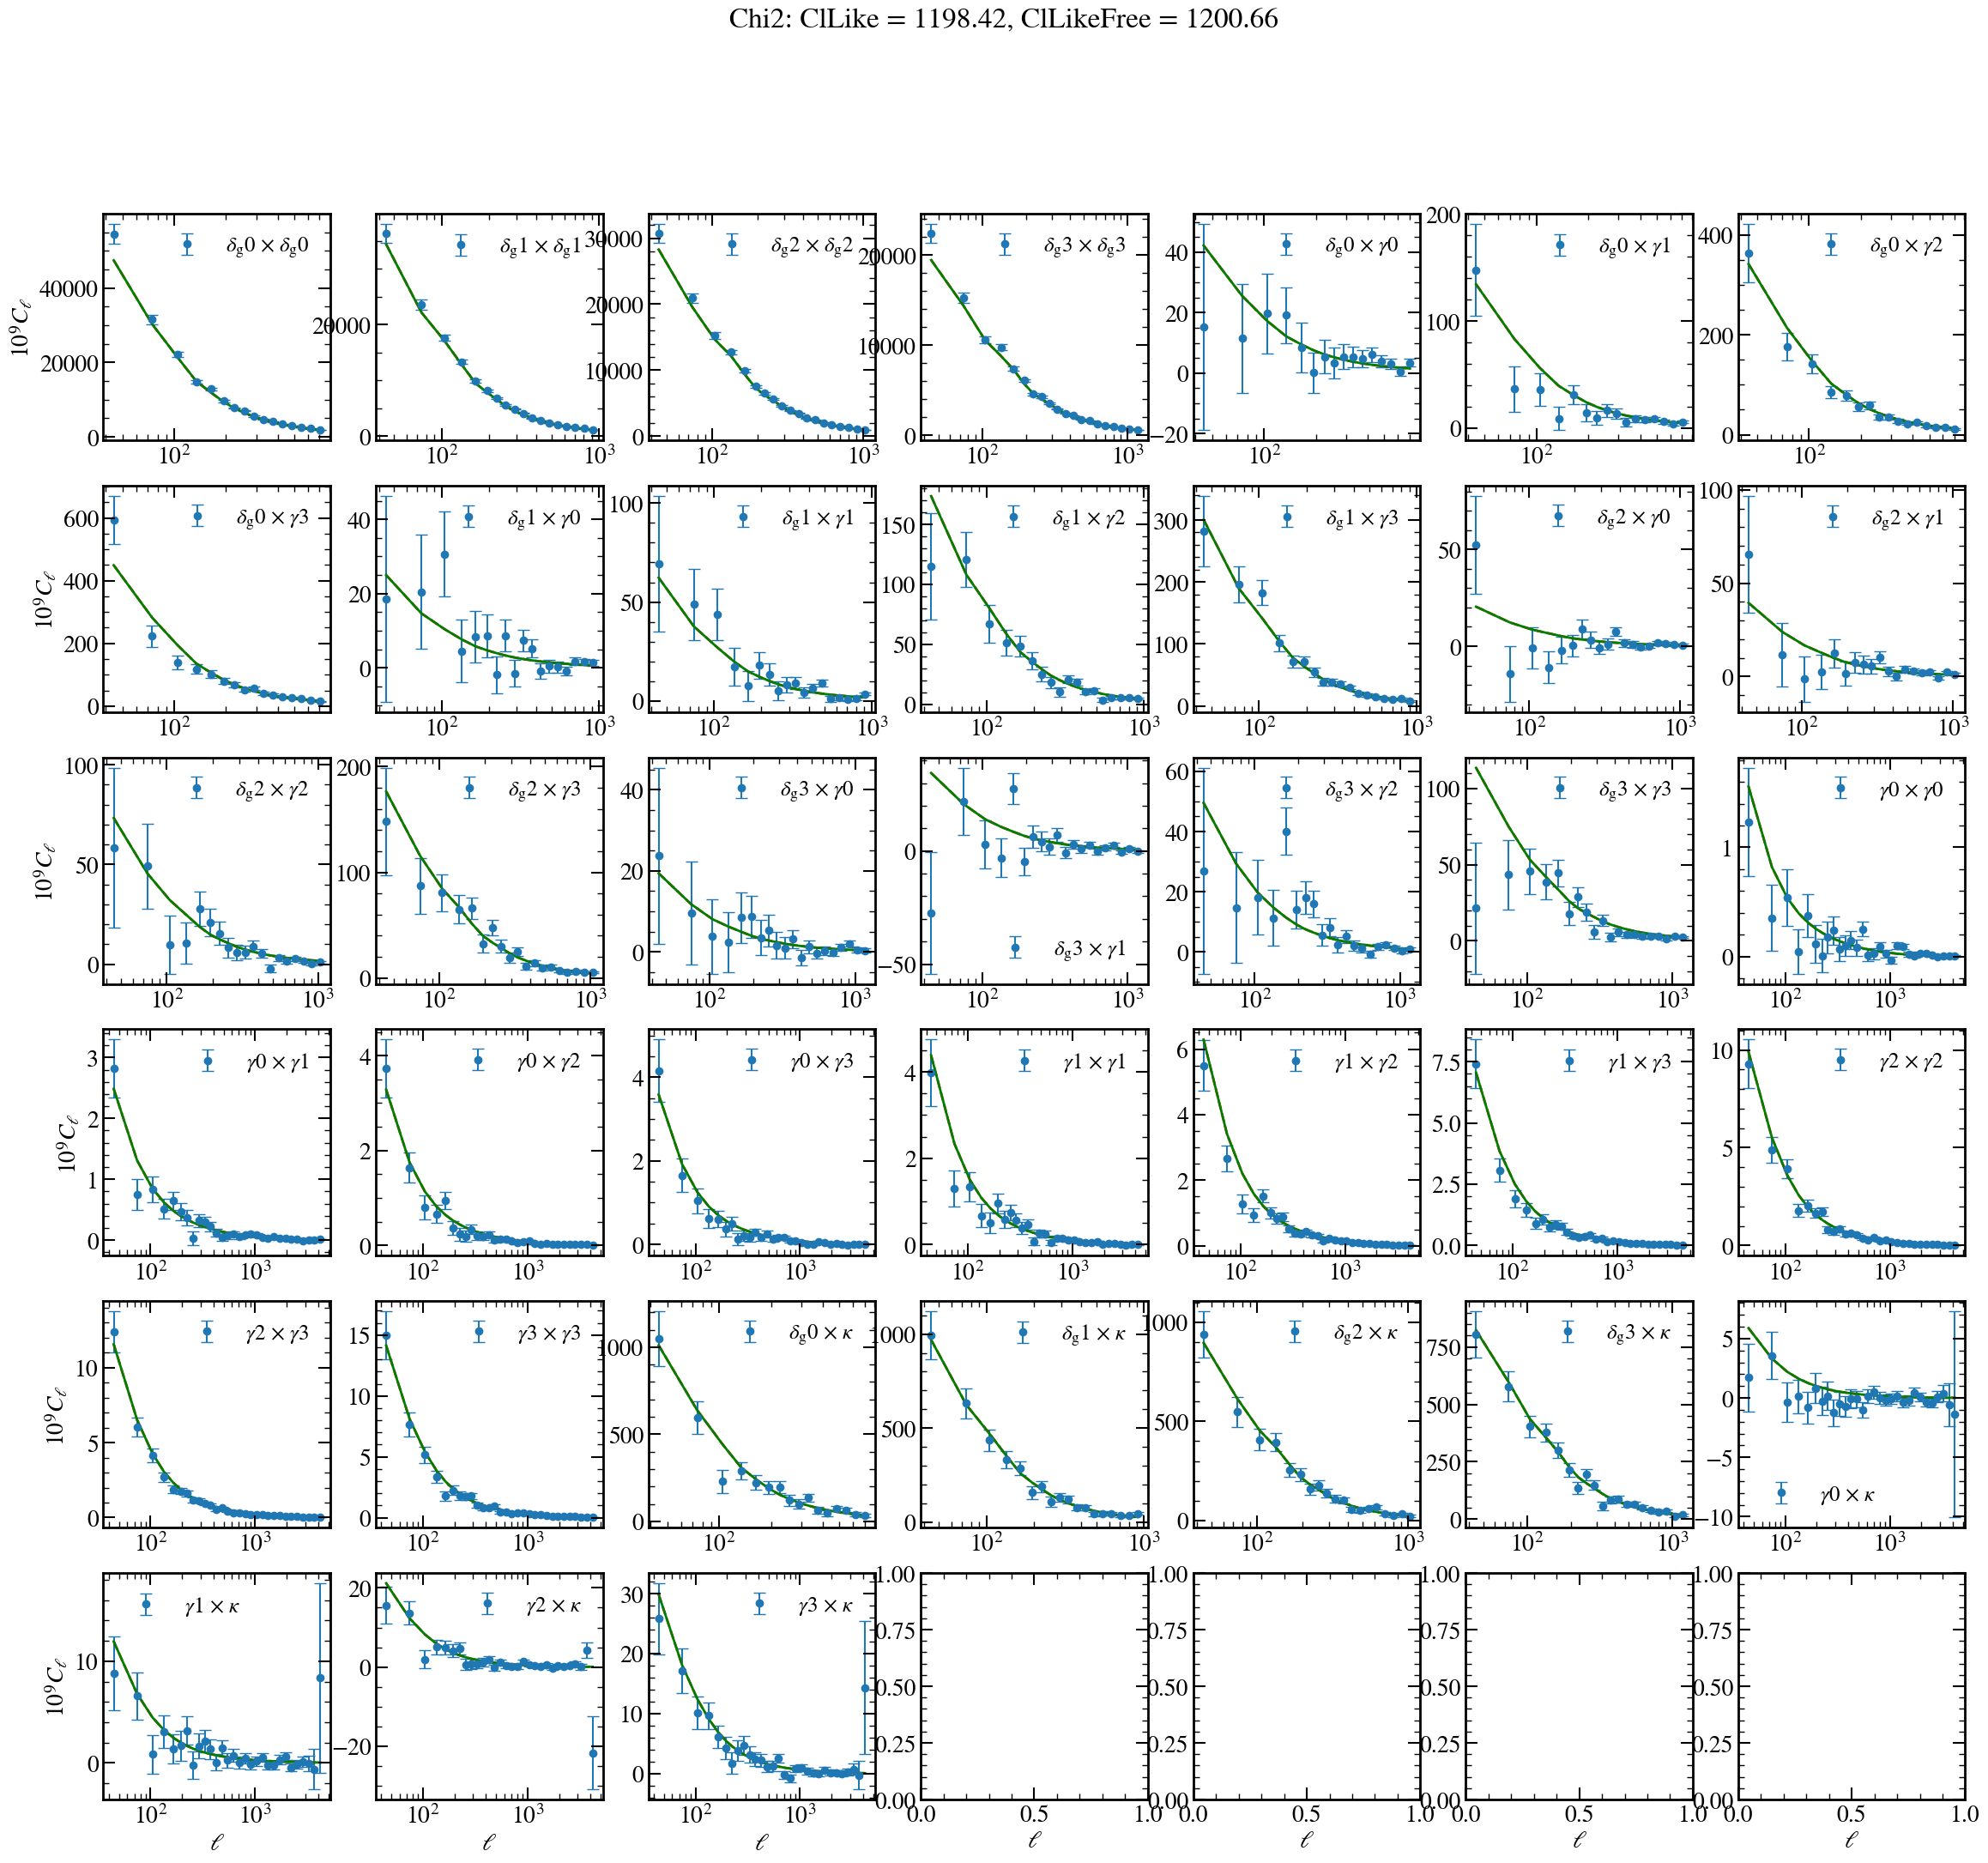

In [6]:
N_subplots = len(ll.cl_meta)
N_rows = int(np.sqrt(N_subplots))
N_cols = N_subplots // N_rows + (N_subplots % N_rows > 0)
Row_hight = 4
Column_width = 4

fig, ax = plt.subplots(N_rows, N_cols, figsize=(N_cols * Column_width, N_rows * Row_hight))

i_start = 0

for ii, clm in enumerate(ll.cl_meta):
    bin1, bin2 = clm['bin_1'], clm['bin_2']
    l_eff, cl, cov = clm['l_eff'], clm['cl'], clm['cov']

    twopt_name = '%s_%s'%(bin1, bin2)
    if twopt_name not in theory_vector:
        twoopt_name = '%s_%s'%(bin2, bin1)
        if twoopt_name not in theory_vector:
            raise ValueError('Theory vector for %s or %s not found'%(twopt_name, twoopt_name))
        twopt_name = twoopt_name
    this_cl_theory = theory_vector[twopt_name]

    inds = ll.cl_meta[ii]['inds']
    cllike_theory = cls_th[inds]

    ax[ii // N_cols, ii % N_cols].errorbar(l_eff, 1e9 *cl, yerr=1e9 * np.sqrt(np.diag(cov)), fmt='o', capsize=5, label=r'%s $\times$ %s'%(mynames[bin1], mynames[bin2]))
    ax[ii // N_cols, ii % N_cols].plot(l_eff, 1e9 * this_cl_theory, 'r--', linewidth=2)
    ax[ii // N_cols, ii % N_cols].plot(l_eff, 1e9 * cllike_theory, 'g-', linewidth=2)
    ax[ii // N_cols, ii % N_cols].legend()
    ax[ii // N_cols, ii % N_cols].set_xscale('log')

for ii in range(N_cols):
    ax[N_rows-1, ii].set_xlabel('$\ell$')
for ii in range(N_rows):
    ax[ii, 0].set_ylabel('$10^9 C_\ell$')

cl_like_chi2, cl_like_free_chi2 = -2*logp.loglike, this_chi2
fig.suptitle('Chi2: ClLike = %.2f, ClLikeFree = %.2f'%(cl_like_chi2, cl_like_free_chi2))

plt.show()

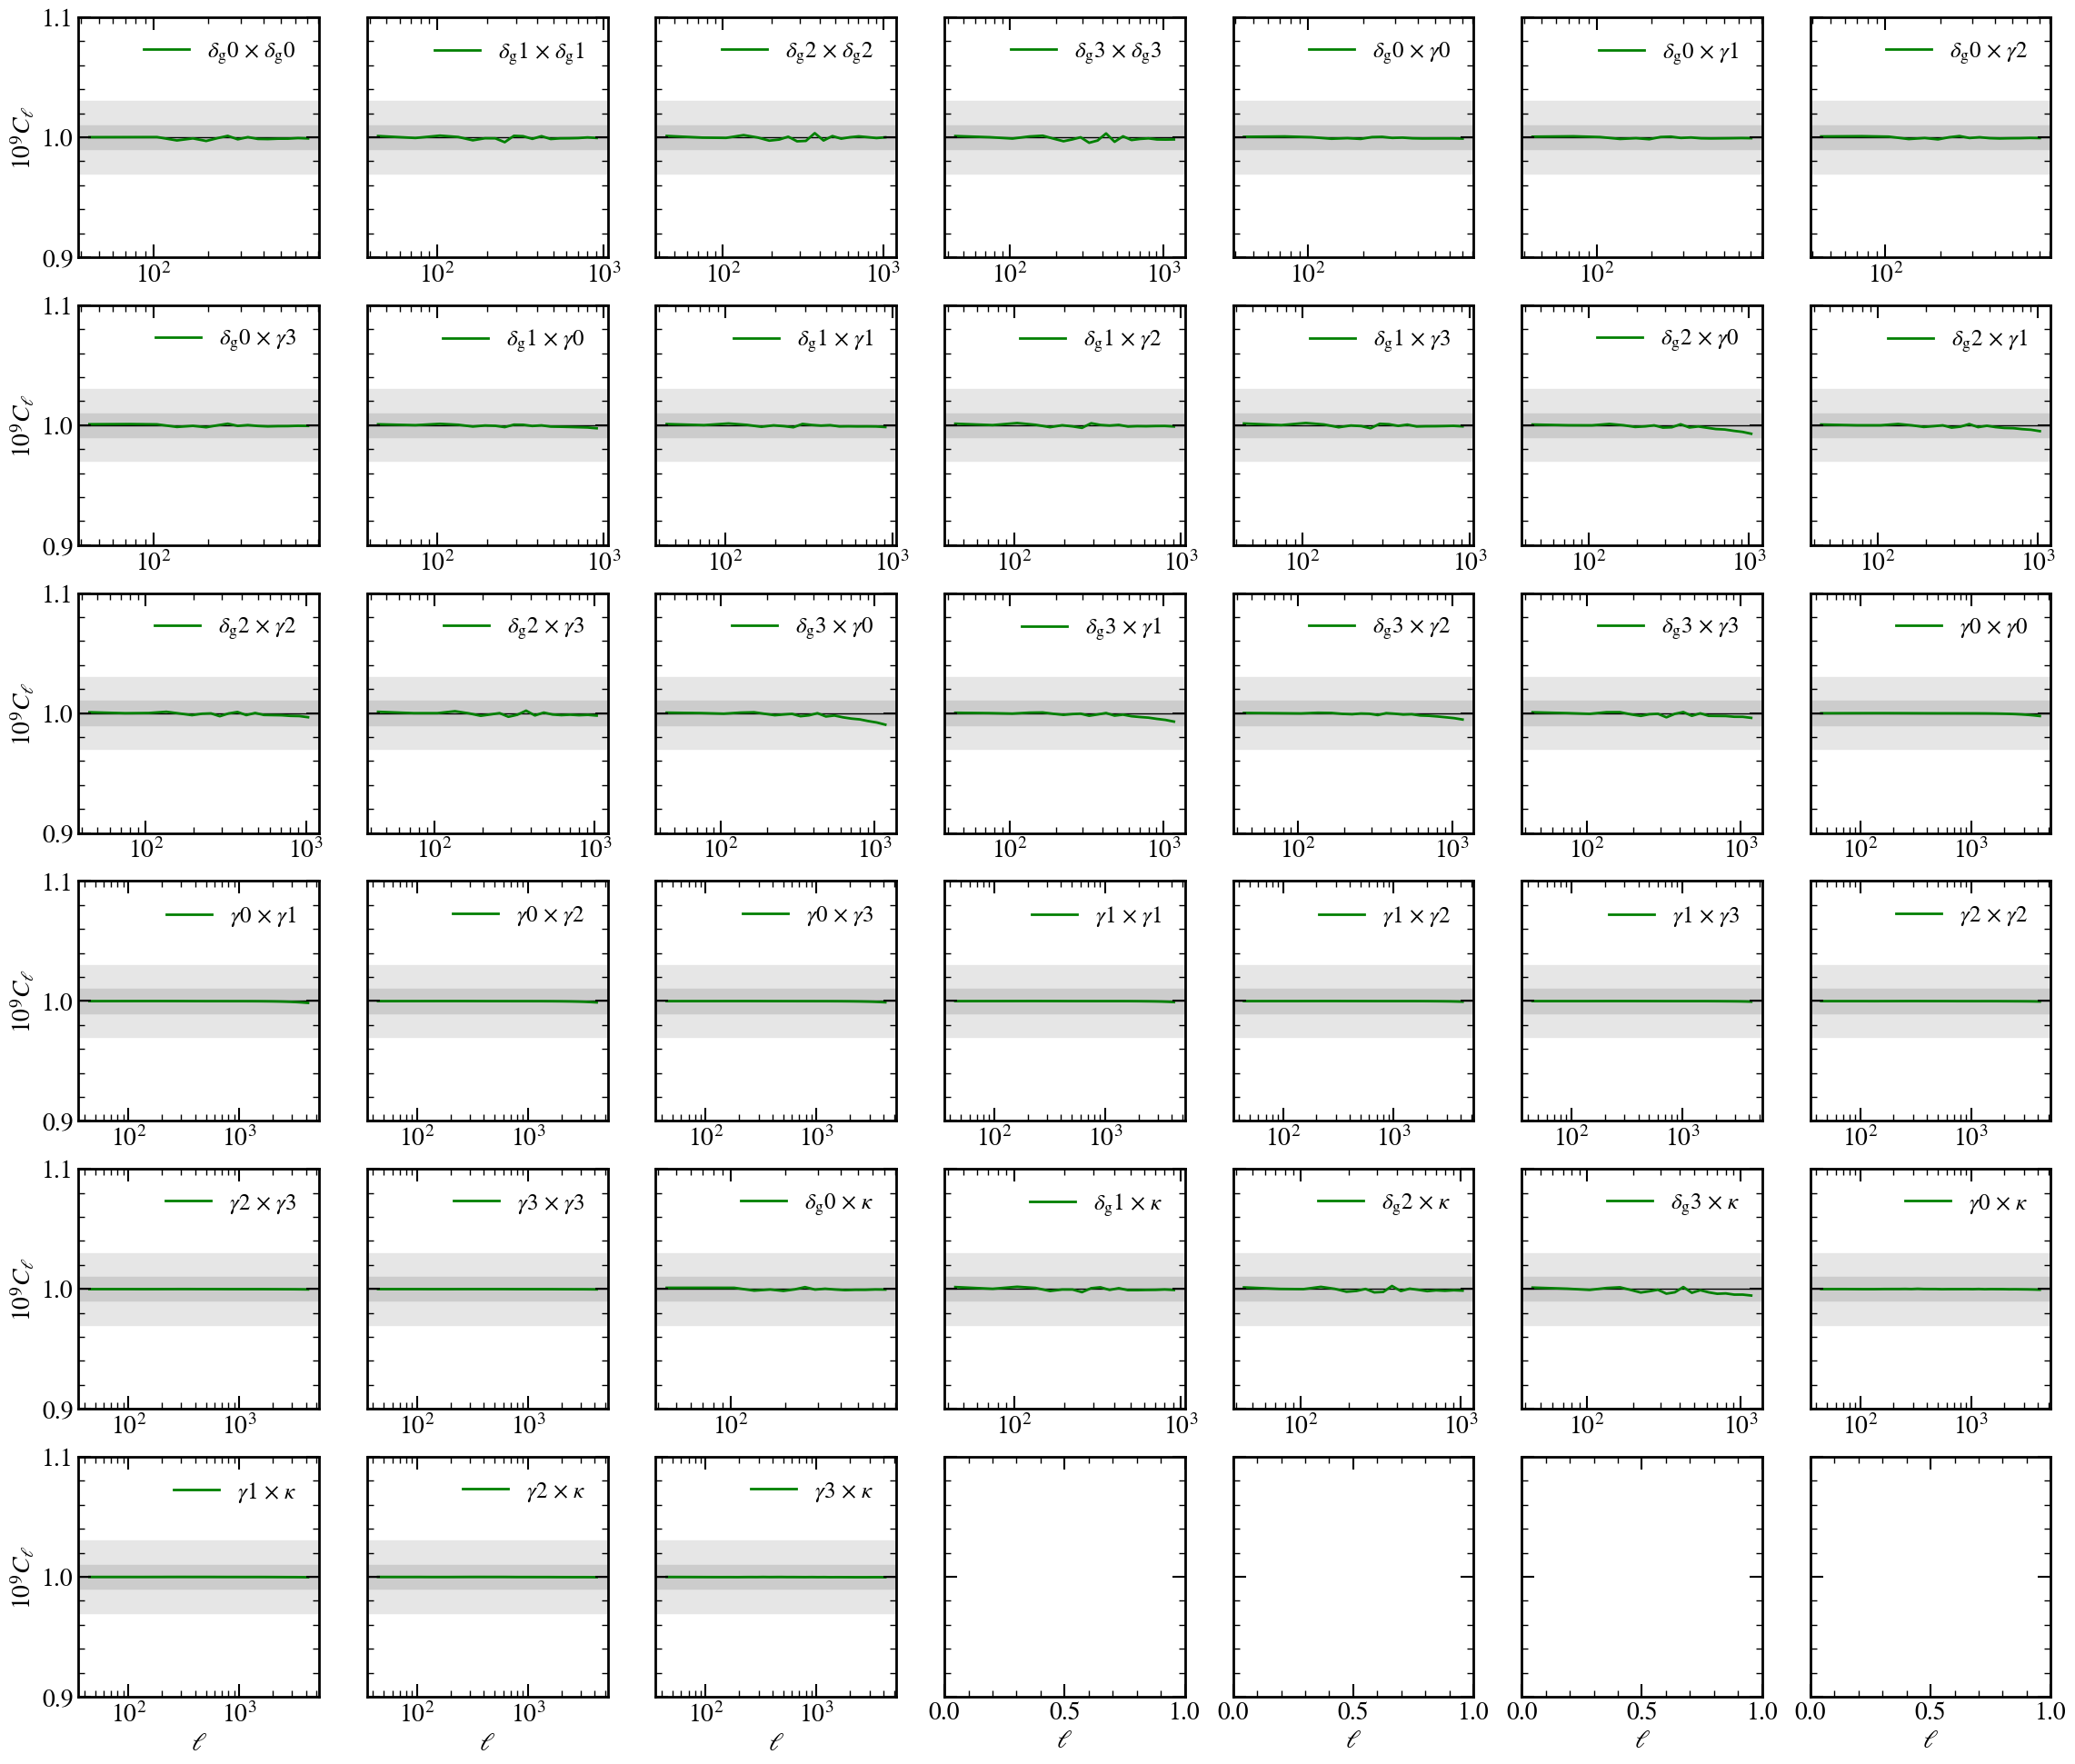

In [7]:
N_subplots = len(ll.cl_meta)
N_rows = int(np.sqrt(N_subplots))
N_cols = N_subplots // N_rows + (N_subplots % N_rows > 0)
Row_hight = 4
Column_width = 4

fig, ax = plt.subplots(N_rows, N_cols, sharey=True, figsize=(N_cols * Column_width, N_rows * Row_hight))

i_start = 0

for ii, clm in enumerate(ll.cl_meta):
    bin1, bin2 = clm['bin_1'], clm['bin_2']
    l_eff, cl, cov = clm['l_eff'], clm['cl'], clm['cov']

    twopt_name = '%s_%s'%(bin1, bin2)
    if twopt_name not in theory_vector:
        twoopt_name = '%s_%s'%(bin2, bin1)
        if twoopt_name not in theory_vector:
            raise ValueError('Theory vector for %s or %s not found'%(twopt_name, twoopt_name))
        twopt_name = twoopt_name
    this_cl_theory = theory_vector[twopt_name]

    inds = ll.cl_meta[ii]['inds']
    cllike_theory = cls_th[inds]

    ax[ii // N_cols, ii % N_cols].axhspan(0.97, 1.03, color='0.9')
    ax[ii // N_cols, ii % N_cols].axhspan(0.99, 1.01, color='0.8')
    ax[ii // N_cols, ii % N_cols].axhline(1.0, color='k', linewidth=1)
    ax[ii // N_cols, ii % N_cols].plot(l_eff, this_cl_theory / cllike_theory, 'g-', linewidth=2, label=r'%s $\times$ %s'%(mynames[bin1], mynames[bin2]))
    ax[ii // N_cols, ii % N_cols].legend()
    ax[ii // N_cols, ii % N_cols].set_xscale('log')
    ax[ii // N_cols, ii % N_cols].set_ylim(0.9, 1.1)

for ii in range(N_cols):
    ax[N_rows-1, ii].set_xlabel('$\ell$')
for ii in range(N_rows):
    ax[ii, 0].set_ylabel('$10^9 C_\ell$')

plt.show()

In [8]:
ii = 18
clm = ll.cl_meta[ii]
name1 = clm['bin_1']
name2 = clm['bin_2']

cosmo_params, bias_params = myll.theory.split_params(sampling_params)

# first, create a ccl cosmology used for the limber integral
ccl_params = myll.theory.sampler_to_ccl_params(cosmo_params)
ccl_cosmo = ccl.Cosmology(**ccl_params,
                      transfer_function=myll.theory.ccl_defaults['transfer_function'],
                      matter_power_spectrum=myll.theory.ccl_defaults['matter_pk'],
                      **myll.theory.ccl_arguments)

# make sure that name1 is the galaxy density bin and name2 is the shear bin
q1 = myll.theory.tracer_qs[name1]
q2 = myll.theory.tracer_qs[name2]
if (q1 == 'galaxy_shear') and (q2 == 'galaxy_density'):
    name1, name2 = name2, name1

# Retrive the magnification bias parameters for the first bin (galaxy density)
if myll.theory.use_magnification_bias:
    s1 = bias_params[myll.theory.magbias_input_params_prefix + '_'+ name1 +'_s']
    S1 = 2 - 5 * s1
else:
    S1 = 0

print(s1)

# Use the emulator to compute galaxy clustering
bias = [bias_params[myll.theory.bias_input_name+'_'+name1+'_'+bname] for bname in myll.theory.bnames]
p3d = myll.theory.heft_calculator.compute_clustering_cross_matter(cosmo_params, ccl_cosmo, bias)
k_gg = p3d['k']
p3d_gm_1 = p3d['gm_1']
p3d_mm = p3d['mm']
a_s = p3d['a_s']

if myll.theory.use_baryons:
    baryon_params = myll.theory._get_baryon_params(bias_params)
    baccoemu_Sk = myll.theory.mpk_calculator.get_baccoemu_Sk(myll.theory.sampler_to_bacco_params(cosmo_params), baryon_params)
    Sk = baccoemu_Sk['Sk2d'](k_gg, a_s)
    p3d_gm_1 *= np.sqrt(Sk)
    p3d_mm *= Sk

if np.all(p3d_gm_1 > 0):
    pk2d_gm_1 = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k_gg), pk_arr=np.log(p3d_gm_1), is_logp=True)
else:
    pk2d_gm_1 = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k_gg), pk_arr=p3d_gm_1, is_logp=False)
if np.all(p3d_mm > 0):
    pk2d_mm = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k_gg), pk_arr=np.log(p3d_mm), is_logp=True)
else:
    pk2d_mm = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k_gg), pk_arr=p3d_mm, is_logp=False)

# Now the projections
dndz = myll.theory._get_nz(name1, bias_params)
z = dndz[0]
oz = np.ones_like(z)
tr1 = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz, bias=(z, oz), has_rsd=False)



# Tracer for magnification bias
trm = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz,
                                bias=(z, z*0), has_rsd=False,
                                mag_bias=(z, oz/5.))
                                # mag_bias=(z, oz*s1))

# Now the shear part

# if there are IA nuisance parameters, apply them here
ia_bias_2 = myll.theory._ia_bias(name2, bias_params)

if myll.theory.shape_model == 'ShapeMultiplicative':
    m2 = bias_params[myll.theory.shape_model_parameters['input_params_prefix'] + '_' + name2 + '_m']
print(name2, m2)

# Now the projections
dndz = myll.theory._get_nz(name2, bias_params)
z = dndz[0]
oz = np.ones_like(z)
tr2 = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz, ia_bias=ia_bias_2)

if myll.theory.sample_cen:
    ls = clm['l_eff']
elif myll.theory.sample_bpw:
    ls = myll.theory.l_sample
else:
    raise RuntimeError("Something went wrong with the sampling!")

cl = ccl.angular_cl(ccl_cosmo, tr1, tr2, ls,
                    limber_integration_method=myll.theory.limber_integration_method,
                    p_of_k_a=pk2d_gm_1) * clm['pixbeam']
cl_smag = ccl.angular_cl(ccl_cosmo, tr2, trm, ls,
                    limber_integration_method=myll.theory.limber_integration_method,
                    p_of_k_a=pk2d_mm) * clm['pixbeam']
cl_gs = (1 + m2) * (cl + S1 * cl_smag)


cl_gs = cl_gs if myll.theory.sample_cen else myll.theory._eval_interp_cl(cl_gs, clm['l_bpw'], clm['w_bpw'])

inds = ll.cl_meta[ii]['inds']
cllike_theory = cls_th[inds]

cl_gs / cllike_theory

0.988
DESY3wl__2 -0.0265481


array([1.00014211, 0.99989944, 0.99972471, 1.00028277, 1.00012762,
       0.99935816, 0.99903889, 0.9996569 , 0.99946313, 0.99835075,
       0.99996577, 0.99948212, 0.99877448, 0.99905179, 0.99801911,
       0.99776863, 0.99720659, 0.99652523, 0.99579989, 0.99464205])

In [9]:
# array([1.02350746, 1.02366152, 1.02293805, 1.02229859, 1.02353202,
#        1.02386048, 1.02681963, 1.02847737, 1.02938091, 1.03200725,
#        1.03427392, 1.03764185, 1.04193308, 1.04698244, 1.05291669,
#        1.05953365])

In [10]:
# pk2d = model.theory['cl_like.Pk'].bacco_calc.pk2d_computed
# pk2d = pk2d['mm_sh_sh']

In [11]:
# trs0 = {}
# trs0_dnames = {}
# trs1 = {}
# trs1_dnames = {}
# for name, q in model.theory['cl_like.Limber'].tracer_qs.items():
#     if name == 'DESY3wl__0':
#         print(q)
#     if q == 'galaxy_density':
#         dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, name, **pars)
#         z = dndz[0]
#         oz = np.ones_like(z)

#         tr = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz, bias=(z, oz),
#                                     has_rsd=False)
#         # Tracer for the unbiased component
#         t0 = None
#         t0n = [None]
#         if model.theory['cl_like.Limber'].bias_model in ['LagrangianPT', 'BaccoPT', 'BaccoHEFT', 'BaccoHEFT_lin']:
#             t0 = tr
#             t0n = ["m"]
#         # Tracers for the biased components
#         t1 = [tr]
#         t1n = ['d1']
#         if model.theory['cl_like.Limber'].is_PT_bias:
#             for bn, dn in zip(['b2', 'bs', 'bk2'], ['d2', 's2', 'k2']):
#                 t1.append(tr)
#                 t1n.append(dn)
#         # Magnification
#         if model.theory['cl_like.Limber'].bin_properties[name]['mag_bias']:
#             # We use s = 1/5 here so that (2-5s)=1 and we multiply by
#             # (2-5s) in cl_total
#             tr = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz,
#                                         bias=(z, z*0), has_rsd=False,
#                                         mag_bias=(z, oz/5.))
#             t1.append(tr)
#             t1n.append("w")
#     elif q == 'galaxy_shear':
#         dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, name, **pars)
#         t0 = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz)
#         print(t0)
#         t0n = ["w"]
#         if model.theory['cl_like.Limber'].ia_model == 'IANone':
#             t1 = None
#             t1n = [None]
#         else:
#             ia_bias = model.theory['cl_like.Limber']._get_ia_bias(ccl_cosmo, name, **pars)
#             t1 = [ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz,
#                                         has_shear=False,
#                                         ia_bias=ia_bias)]
#             t1n = ['w']
#     elif q == 'cmb_convergence':
#         # B.H. TODO: pass z_source as parameter to the YAML file
#         t0 = ccl.CMBLensingTracer(ccl_cosmo, z_source=1100)
#         t0n = ['w']
#         t1 = None
#         t1n = [None]

#     trs0[name] = t0
#     trs1[name] = t1
#     trs0_dnames[name] = t0n
#     trs1_dnames[name] = t1n

# print(trs0['DESY3wl__0'])
# print(trs1['DESI_LRG__0'])

In [12]:
# trs0, trs1, trs0_dnames, trs1_dnames = model.theory['cl_like.Limber']._get_tracers(ccl_cosmo, **pars)
# for clm in model.theory['cl_like.Limber'].cl_meta:

#     n1 = clm['bin_1']
#     n2 = clm['bin_2']

#     if (n2 != 'DESY3wl__0') or (n1 != 'DESI_LRG__0'):
#         continue
#     print('n1', n1, 'n2', n2)


#     t0_1 = trs0[n1]
#     t0_2 = trs0[n2]
#     t1_1 = trs1[n1]
#     t1_2 = trs1[n2]
#     # The unbiased tracers have only one element in the list "m" or
#     # "w".
#     t0dn_1 = trs0_dnames[n1][0]
#     t0dn_2 = trs0_dnames[n2][0]
#     t1dn_1 = trs1_dnames[n1]
#     t1dn_2 = trs1_dnames[n2]
#     # 00: unbiased x unbiased
#     if t0_1 and t0_2:
#         print('unbiased x unbiased')
#         pk = pk2d
#         cl00 = ccl.angular_cl(ccl_cosmo, t0_1, t0_2, ls,
#                                 limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
#                                 p_of_k_a=pk) * clm['pixbeam']
#     # 01: unbiased x biased
#     if t0_1 and (t1_2 is not None):
#         print('unbiased x biased')
#         cl01 = []
#         for t12, dn in zip(t1_2, t1dn_2):
#             pk = pk2d
#             if pk is not None:
#                 cl = ccl.angular_cl(ccl_cosmo, t0_1, t12, ls,
#                                     limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
#                                     p_of_k_a=pk) * clm['pixbeam']
#             else:
#                 cl = np.zeros_like(ls)
#             cl01.append(cl)
#         print(len(cl01))
#         cl01 = np.array(cl01)

#     # 10: biased x unbiased
#     if n1 == n2:
#         cl10 = cl01
#     else:
#         if t0_2 and (t1_1 is not None):
#             cl10 = []
#             for t11, dn in zip(t1_1, t1dn_1):
#                 pk = pk2d
#                 if pk is not None:
#                     cl = ccl.angular_cl(ccl_cosmo, t11, t0_2, ls,
#                                         limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
#                                         p_of_k_a=pk) * clm['pixbeam']
#                 else:
#                     cl = np.zeros_like(ls)
#                 cl10.append(cl)
#             cl10 = np.array(cl10)

#     # 11: biased x biased
#     if (t1_1 is not None) and (t1_2 is not None):
#         print('biased x biased')
#         cl11 = np.zeros([len(t1_1), len(t1_2), len(ls)])
#         print(len(t1_1), len(t1_2))
#         autocorr = n1 == n2
#         for i1, (t11, dn1) in enumerate(zip(t1_1, t1dn_1)):
#             for i2, (t12, dn2) in enumerate(zip(t1_2, t1dn_2)):
#                 if autocorr and i2 < i1:
#                     cl11[i1, i2] = cl11[i2, i1]
#                 else:
#                     pk = pk2d
#                     if pk is not None:
#                         cl = ccl.angular_cl(ccl_cosmo, t11, t12, ls,
#                                             limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
#                                             p_of_k_a=pk) * clm['pixbeam']
#                     else:
#                         cl = np.zeros_like(ls)
#                     cl11[i1, i2, :] = cl

# print(trs0_dnames[n1])
# print(trs0_dnames[n2])
# print(trs1_dnames[n1])
# print(trs1_dnames[n2])
# cl11

In [13]:
# print(cl_gs / cl01)